# 01 · Original Approach (the version with data leakage)

This is my **first attempt**. I keep it here on purpose, because the mistake in it taught me an important lesson.

**Steps:**
1. Look at how rare depression cases are (31 out of 1,200)
2. Train a baseline Logistic Regression model
3. Train **CTGAN** on the 31 depression cases and create 1,000 synthetic cases
4. Add the synthetic cases to the data, **then** split into train and test, and retrain

⚠️ **The problem:** because the synthetic rows were added *before* the split, most depression cases in the test set are synthetic. The model is tested on data that looks just like what it learned from, so the recall looks much better than it really is. See notebook 02 for the corrected version.

In [1]:
import random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             f1_score, confusion_matrix, classification_report)
from sdv.single_table import CTGANSynthesizer
from sdv.metadata import Metadata

warnings.filterwarnings("ignore")

# Fix the random seeds so the results are repeatable
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

df = pd.read_csv("../data/Teen_Mental_Health_Dataset.csv")
categorical_cols = ['gender', 'platform_usage', 'social_interaction_level']
print(df.shape)

(1200, 13)


## 1. How imbalanced is the data?

depression_label
0    1169
1      31
Name: count, dtype: int64
depression_label
0    97.42
1     2.58
Name: count, dtype: float64 %


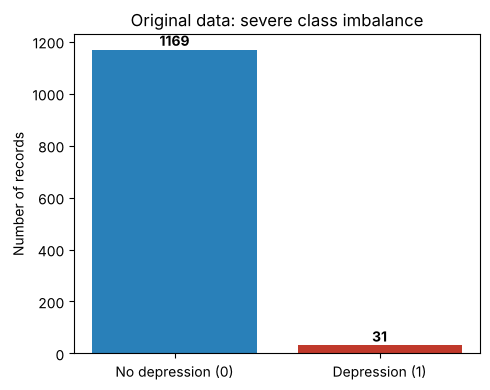

In [2]:
counts = df['depression_label'].value_counts()
print(counts)
print((counts / len(df) * 100).round(2), '%')

plt.figure(figsize=(5, 4))
plt.bar(['No depression (0)', 'Depression (1)'], counts.values, color=['#2980B9', '#C0392B'])
plt.title('Original data: severe class imbalance')
plt.ylabel('Number of records')
for i, v in enumerate(counts.values):
    plt.text(i, v + 15, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('../images/class_imbalance.png', dpi=150)
plt.show()

## 2. Baseline model (no synthetic data)

In [3]:
def encode(data, encoders):
    """Turn text columns into numbers with the same encoders every time."""
    data = data.copy()
    for col in categorical_cols:
        known = set(encoders[col].classes_)
        data[col] = data[col].astype(str).apply(lambda x: x if x in known else encoders[col].classes_[0])
        data[col] = encoders[col].transform(data[col])
    return data.drop(columns=['depression_label']), data['depression_label']

encoders = {col: LabelEncoder().fit(df[col].astype(str)) for col in categorical_cols}

X, y = encode(df, encoders)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED, stratify=y)
print(f"Depression cases in test set: {y_test.sum()} out of {len(y_test)}")

baseline = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train, y_train)
y_pred = baseline.predict(X_test)
print(classification_report(y_test, y_pred, target_names=['No depression', 'Depression'], zero_division=0))

Depression cases in test set: 8 out of 300
               precision    recall  f1-score   support

No depression       0.98      1.00      0.99       292
   Depression       1.00      0.38      0.55         8

     accuracy                           0.98       300
    macro avg       0.99      0.69      0.77       300
 weighted avg       0.98      0.98      0.98       300



## 3. Train CTGAN on the 31 depression cases

In [4]:
minority_real = df[df['depression_label'] == 1].reset_index(drop=True)
metadata = Metadata.detect_from_dataframe(minority_real)

synthesizer = CTGANSynthesizer(metadata, epochs=300)
synthesizer.fit(minority_real)

synthetic = synthesizer.sample(num_rows=1000)
synthetic['depression_label'] = 1
synthetic.head()

,age,gender,daily_social_media_hours,platform_usage,sleep_hours,screen_time_before_sleep,academic_performance,physical_activity,social_interaction_level,stress_level,anxiety_level,addiction_level,depression_label
0,15,female,5.3,Both,4.3,3.0,2.85,1.1,medium,7,7,5,1
1,16,female,5.4,TikTok,5.5,2.9,3.68,0.0,low,10,8,4,1
2,16,female,5.1,Instagram,5.0,2.5,3.79,0.0,medium,7,9,7,1
3,14,male,7.0,Instagram,4.8,1.9,3.45,0.0,high,9,9,10,1
4,15,female,7.1,TikTok,5.2,3.0,3.79,0.9,high,8,7,9,1


### Does the synthetic data look like the real data?

In [5]:
cols = ['stress_level', 'anxiety_level', 'sleep_hours', 'daily_social_media_hours', 'addiction_level']
pd.DataFrame({
    'Real mean (n=31)': minority_real[cols].mean(),
    'Synthetic mean (n=1000)': synthetic[cols].mean(),
    'Real std': minority_real[cols].std(),
    'Synthetic std': synthetic[cols].std(),
}).round(2)

,Real mean (n=31),Synthetic mean (n=1000),Real std,Synthetic std
stress_level,8.48,8.38,1.21,1.12
anxiety_level,8.61,8.19,1.05,1.02
sleep_hours,4.76,4.54,0.57,0.48
daily_social_media_hours,6.72,6.85,1.01,0.96
addiction_level,5.32,6.76,3.03,2.70


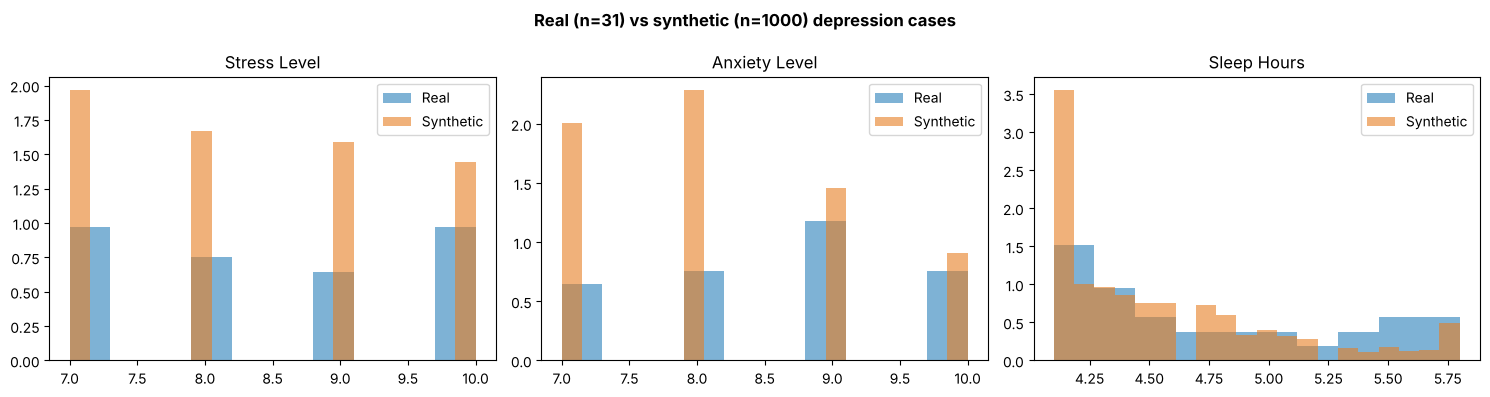

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Real (n=31) vs synthetic (n=1000) depression cases', fontweight='bold')
for ax, col in zip(axes, ['stress_level', 'anxiety_level', 'sleep_hours']):
    ax.hist(minority_real[col], bins=10, alpha=0.6, color='#2980B9', label='Real', density=True)
    ax.hist(synthetic[col], bins=20, alpha=0.6, color='#E67E22', label='Synthetic', density=True)
    ax.set_title(col.replace('_', ' ').title())
    ax.legend()
plt.tight_layout()
plt.savefig('../images/real_vs_synthetic.png', dpi=150)
plt.show()

## 4. Add synthetic data, then split (⚠️ data leakage)

In [7]:
df_balanced = pd.concat([df, synthetic], ignore_index=True)
X_bal, y_bal = encode(df_balanced, encoders)
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_bal, y_bal, test_size=0.25, random_state=SEED, stratify=y_bal)

print(f"Depression cases in test set: {y_test_b.sum()} out of {len(y_test_b)}")
print("Most of these test cases are synthetic, not real teenagers.")

model_b = LogisticRegression(max_iter=1000, random_state=SEED).fit(X_train_b, y_train_b)
y_pred_b = model_b.predict(X_test_b)
print(classification_report(y_test_b, y_pred_b, target_names=['No depression', 'Depression'], zero_division=0))

Depression cases in test set: 258 out of 550
Most of these test cases are synthetic, not real teenagers.
               precision    recall  f1-score   support

No depression       0.96      0.98      0.97       292
   Depression       0.97      0.96      0.96       258

     accuracy                           0.97       550
    macro avg       0.97      0.97      0.97       550
 weighted avg       0.97      0.97      0.97       550



In [8]:
summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Recall (depression)', 'Precision (depression)', 'F1 (depression)'],
    'Baseline': [accuracy_score(y_test, y_pred), recall_score(y_test, y_pred),
                 precision_score(y_test, y_pred, zero_division=0), f1_score(y_test, y_pred)],
    'CTGAN (leaky test set)': [accuracy_score(y_test_b, y_pred_b), recall_score(y_test_b, y_pred_b),
                               precision_score(y_test_b, y_pred_b, zero_division=0), f1_score(y_test_b, y_pred_b)],
}).round(3)
summary

,Metric,Baseline,CTGAN (leaky test set)
0,Accuracy,0.983,0.967
1,Recall (depression),0.375,0.957
2,Precision (depression),1.000,0.972
3,F1 (depression),0.545,0.965


These numbers look great, but they are **not a fair test**. In notebook 02 I fix the method and test only on real teenagers.